In [30]:
from pathlib import Path

print("Diretório de trabalho do kernel:", Path.cwd())
print()
for pasta in [Path.cwd(), Path.cwd().parent]:
    bruto = pasta / "data" / "raw"
    print(f"{pasta}  ->  data/raw existe? {bruto.exists()}")


Diretório de trabalho do kernel: c:\projetos\projeto-olist\notebooks

c:\projetos\projeto-olist\notebooks  ->  data/raw existe? False
c:\projetos\projeto-olist  ->  data/raw existe? True


In [31]:
import pandas as pd

RAW = Path.cwd().parent / "data" / "raw"
orders = pd.read_csv(RAW / "olist_orders_dataset.csv")

print("Formato:", orders.shape)
print()
orders.head()

Formato: (99441, 8)



KeyboardInterrupt: 

In [ ]:
print("=== TIPOS DE DADOS ===")
print(orders.dtypes)
print()
print("=== STATUS DOS PEDIDOS ===")
print(orders["order_status"].value_counts())

=== TIPOS DE DADOS ===
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

=== STATUS DOS PEDIDOS ===
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [ ]:
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for coluna in colunas_data:
    orders[coluna] = pd.to_datetime(orders[coluna], errors="coerce")

print(orders.dtypes)
print()
print("Datas convertidas. Nulos por coluna:")
print(orders[colunas_data].isna().sum())


order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Datas convertidas. Nulos por coluna:
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

RAW = Path.cwd().parent / "data" / "raw"

orders = pd.read_csv(RAW / "olist_orders_dataset.csv")

colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for coluna in colunas_data:
    orders[coluna] = pd.to_datetime(orders[coluna], errors="coerce")

print("Dados carregados.")
print("Formato:", orders.shape)
print()
orders.head()

Dados carregados.
Formato: (99441, 8)



,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [ ]:
orders["dias_atraso"] = (
    (orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"])
    .dt.days
)

orders["atrasou"] = np.where(orders["dias_atraso"] > 0, "Sim", "Não")

orders["horas_aprovacao"] = (
    (orders["order_approved_at"] - orders["order_purchase_timestamp"])
    .dt.total_seconds() / 3600
)

orders["horas_despacho"] = (
    (orders["order_delivered_carrier_date"] - orders["order_approved_at"])
    .dt.total_seconds() / 3600
)

orders["dias_entrega_real"] = (
    (orders["order_delivered_customer_date"] - orders["order_delivered_carrier_date"])
    .dt.days
)

print("Colunas criadas.")
print(orders[["dias_atraso", "atrasou", "horas_aprovacao", "horas_despacho", "dias_entrega_real"]].head())
print()
print("Atrasos por status:")
print(orders.groupby("order_status")["dias_atraso"].mean().round(2))

Colunas criadas.
   dias_atraso atrasou  horas_aprovacao  horas_despacho  dias_entrega_real
0         -8.0     Não         0.178333       56.795833                6.0
1         -6.0     Não        30.713889       11.109167               12.0
2        -18.0     Não         0.276111        4.910278                9.0
3        -13.0     Não         0.298056       89.900000                9.0
4        -10.0     Não         1.030556       21.434722                1.0

Atrasos por status:
order_status
approved         NaN
canceled      -27.83
created          NaN
delivered     -11.88
invoiced         NaN
processing       NaN
shipped          NaN
unavailable      NaN
Name: dias_atraso, dtype: float64


In [ ]:
print("=== ATRASO (apenas pedidos entregues) ===")
entregues = orders[orders["order_status"] == "delivered"].copy()

print("Total de entregues:", len(entregues))
print()
print(entregues["dias_atraso"].describe())
print()
print("Faixas de atraso:")
faixas = pd.cut(entregues["dias_atraso"], bins=[-999, -30, -15, -7, -1, 0, 7, 15, 30, 999], right=False)
print(faixas.value_counts().sort_index())

=== ATRASO (apenas pedidos entregues) ===
Total de entregues: 96478

count    96470.000000
mean       -11.875889
std         10.182105
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: dias_atraso, dtype: float64

Faixas de atraso:
dias_atraso
[-999, -30)     2352
[-30, -15)     27242
[-15, -7)      41709
[-7, -1)       15879
[-1, 0)         1462
[0, 7)          4481
[7, 15)         1961
[15, 30)        1024
[30, 999)        360
Name: count, dtype: int64


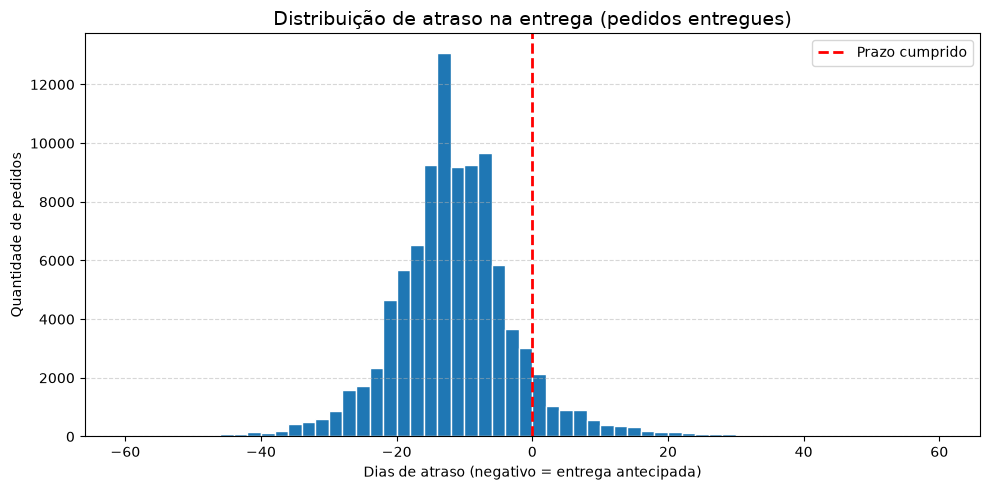

In [ ]:
import matplotlib.pyplot as plt

atrasos_plot = entregues[entregues["dias_atraso"].between(-60, 60)]["dias_atraso"]

plt.figure(figsize=(10, 5))
plt.hist(atrasos_plot, bins=60, color="#1f77b4", edgecolor="white")
plt.axvline(0, color="red", linestyle="--", linewidth=2, label="Prazo cumprido")
plt.title("Distribuição de atraso na entrega (pedidos entregues)", fontsize=14)
plt.xlabel("Dias de atraso (negativo = entrega antecipada)")
plt.ylabel("Quantidade de pedidos")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
customers = pd.read_csv(RAW / "olist_customers_dataset.csv")
sellers = pd.read_csv(RAW / "olist_sellers_dataset.csv")
geoloc = pd.read_csv(RAW / "olist_geolocation_dataset.csv")

print("CLIENTES")
print("Formato:", customers.shape)
print(customers.head())
print()
print("VENDEDORES")
print("Formato:", sellers.shape)
print(sellers.head())
print()
print("GEOLOCALIZAÇÃO")
print("Formato:", geoloc.shape)
print(geoloc.head())

CLIENTES
Formato: (99441, 5)
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  

VENDEDORES
Formato: (3095, 4)
                          seller_id  seller_zip_code_prefix  \
0  3442f8959a84dea7ee197c632cb

In [ ]:
order_items = pd.read_csv(RAW / "olist_order_items_dataset.csv")
payments = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(RAW / "olist_order_reviews_dataset.csv")
products = pd.read_csv(RAW / "olist_products_dataset.csv")
categories = pd.read_csv(RAW / "product_category_name_translation.csv")

todos = {
    "orders": orders,
    "customers": customers,
    "sellers": sellers,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "products": products,
    "geoloc": geoloc,
    "categories": categories,
}

for nome, tabela in todos.items():
    print(f"{nome:20s} → {tabela.shape[0]:>7,} linhas × {tabela.shape[1]:>3} colunas")
    

orders               →  99,441 linhas ×  13 colunas
customers            →  99,441 linhas ×   5 colunas
sellers              →   3,095 linhas ×   4 colunas
order_items          → 112,650 linhas ×   7 colunas
payments             → 103,886 linhas ×   5 colunas
reviews              →  99,224 linhas ×   7 colunas
products             →  32,951 linhas ×   9 colunas
geoloc               → 1,000,163 linhas ×   5 colunas
categories           →      71 linhas ×   2 colunas


In [ ]:
for nome, tabela in todos.items():
    print(f"\n{'='*60}")
    print(f"  {nome.upper()}  ({tabela.shape[0]:,} linhas × {tabela.shape[1]} colunas)")
    print(f"{'='*60}")
    print(tabela.dtypes)
    print()
    nulos = tabela.isna().sum()
    nulos = nulos[nulos > 0]
    if len(nulos) > 0:
        print("Colunas com nulos:")
        print(nulos)
    else:
        print("Sem nulos.")


  ORDERS  (99,441 linhas × 13 colunas)
order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dias_atraso                             float64
atrasou                                     str
horas_aprovacao                         float64
horas_despacho                          float64
dias_entrega_real                       float64
dtype: object

Colunas com nulos:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dias_atraso                      2965
horas_aprovacao                   160
horas_despacho                   1797
dias_entrega_real                2966
dtype: int64

  CUSTOMERS  (99,441 l

In [ ]:
from pathlib import Path
import pandas as pd

RAW = Path.cwd().parent / "data" / "raw"

geoloc = pd.read_csv(RAW / "olist_geolocation_dataset.csv")

print(f"Formato: {geoloc.shape[0]:,} linhas × {geoloc.shape[1]} colunas")
print()
print("Colunas:", list(geoloc.columns))
print()
print(geoloc.head())

Formato: 1,000,163 linhas × 5 colunas

Colunas: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

   geolocation_zip_code_prefix  geolocation_lat  geolocation_lng  \
0                         1037       -23.545621       -46.639292   
1                         1046       -23.546081       -46.644820   
2                         1046       -23.546129       -46.642951   
3                         1041       -23.544392       -46.639499   
4                         1035       -23.541578       -46.641607   

  geolocation_city geolocation_state  
0        sao paulo                SP  
1        sao paulo                SP  
2        sao paulo                SP  
3        sao paulo                SP  
4        sao paulo                SP  


In [ ]:
zip_unicos = geoloc["geolocation_zip_code_prefix"].nunique()
print(f"Zip codes únicos: {zip_unicos:,}")
print(f"Linhas totais:    {geoloc.shape[0]:,}")
print(f"Repetições por zip (média): {geoloc.shape[0] / zip_unicos:.1f}x")

Zip codes únicos: 19,015
Linhas totais:    1,000,163
Repetições por zip (média): 52.6x


In [ ]:
geoloc_dedup = (
    geoloc
    .groupby("geolocation_zip_code_prefix")
    .agg(
        geolocation_lat=("geolocation_lat", "mean"),
        geolocation_lng=("geolocation_lng", "mean"),
        geolocation_city=("geolocation_city", lambda x: x.mode()[0] if not x.mode().empty else x.iloc[0]),
        geolocation_state=("geolocation_state", lambda x: x.mode()[0] if not x.mode().empty else x.iloc[0]),
    )
    .reset_index()
)

print(f"Depois do dedup: {geoloc_dedup.shape[0]:,} linhas")
print(f"Redução: {geoloc.shape[0]:,} → {geoloc_dedup.shape[0]:,}")
print()
print(geoloc_dedup.head())

KeyboardInterrupt: 

In [ ]:
order_items = pd.read_csv(RAW / "olist_order_items_dataset.csv")

order_items["preco_total_item"] = (order_items["price"] + order_items["freight_value"]).round(2)

print("order_items — coluna criada:")
print(order_items[["order_id", "order_item_id", "price", "freight_value", "preco_total_item"]].head())
print()
print("Formato:", order_items.shape)

order_items — coluna criada:
                           order_id  order_item_id   price  freight_value  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   58.90          13.29   
1  00018f77f2f0320c557190d7a144bdd3              1  239.90          19.93   
2  000229ec398224ef6ca0657da4fc703e              1  199.00          17.87   
3  00024acbcdf0a6daa1e931b038114c75              1   12.99          12.79   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1  199.90          18.14   

   preco_total_item  
0             72.19  
1            259.83  
2            216.87  
3             25.78  
4            218.04  

Formato: (112650, 8)


In [ ]:
payments = pd.read_csv(RAW / "olist_order_payments_dataset.csv")

print("Tipos de pagamento:")
print(payments["payment_type"].value_counts())
print()
print("Parcelas:")
print(payments["payment_installments"].describe())

Tipos de pagamento:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Parcelas:
count    103886.000000
mean          2.853349
std           2.687051
min           0.000000
25%           1.000000
50%           1.000000
75%           4.000000
max          24.000000
Name: payment_installments, dtype: float64


In [ ]:
reviews = pd.read_csv(RAW / "olist_order_reviews_dataset.csv")

reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"], errors="coerce")
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"], errors="coerce")

reviews["horas_resposta"] = (
    (reviews["review_answer_timestamp"] - reviews["review_creation_date"])
    .dt.total_seconds() / 3600
)

reviews["sentimento"] = pd.cut(
    reviews["review_score"],
    bins=[0, 2, 3, 5],
    labels=["negativo", "neutro", "positivo"],
    include_lowest=True,
)

print("reviews — colunas criadas:")
print(reviews[["review_id", "review_score", "sentimento", "horas_resposta"]].head())
print()
print("Distribuição de sentimento:")
print(reviews["sentimento"].value_counts())

reviews — colunas criadas:
                          review_id  review_score sentimento  horas_resposta
0  7bc2406110b926393aa56f80a40eba40             4   positivo       21.783056
1  80e641a11e56f04c1ad469d5645fdfde             5   positivo       27.086944
2  228ce5500dc1d8e020d8d1322874b6f0             5   positivo       38.606667
3  e64fb393e7b32834bb789ff8bb30750e             5   positivo       22.035000
4  f7c4243c7fe1938f181bec41a392bdeb             5   positivo       34.448056

Distribuição de sentimento:
sentimento
positivo    76470
negativo    14575
neutro       8179
Name: count, dtype: int64


In [ ]:
products = pd.read_csv(RAW / "olist_products_dataset.csv")
categories = pd.read_csv(RAW / "product_category_name_translation.csv")

# Juntar tradução das categorias
products = products.merge(categories, on="product_category_name", how="left")

# Colunas derivadas
products["volume_cm3"] = (
    products["product_length_cm"]
    * products["product_height_cm"]
    * products["product_width_cm"]
)

products["peso_kg"] = products["product_weight_g"] / 1000

print("products — colunas criadas:")
print(products[["product_id", "product_category_name_english", "volume_cm3", "peso_kg"]].head())
print()
print("Categorias sem tradução:", products["product_category_name_english"].isna().sum())

products — colunas criadas:
                         product_id product_category_name_english  volume_cm3  \
0  1e9e8ef04dbcff4541ed26657ea517e5                     perfumery      2240.0   
1  3aa071139cb16b67ca9e5dea641aaa2f                           art     10800.0   
2  96bd76ec8810374ed1b65e291975717f                sports_leisure      2430.0   
3  cef67bcfe19066a932b7673e239eb23d                          baby      2704.0   
4  9dc1a7de274444849c219cff195d0b71                    housewares      4420.0   

   peso_kg  
0    0.225  
1    1.000  
2    0.154  
3    0.371  
4    0.625  

Categorias sem tradução: 623


In [ ]:
orders_rfm = pd.read_csv(RAW / "olist_orders_dataset.csv")

colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in colunas_data:
    orders_rfm[col] = pd.to_datetime(orders_rfm[col], errors="coerce")

customers = pd.read_csv(RAW / "olist_customers_dataset.csv")

# Join por customer_id (não order_id!)
orders_rfm = orders_rfm.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Filtrar apenas entregues
entregues = orders_rfm[orders_rfm["order_status"] == "delivered"].copy()

# Juntar com order_items
order_items_rfm = pd.read_csv(RAW / "olist_order_items_dataset.csv")
order_items_rfm["preco_total_item"] = (order_items_rfm["price"] + order_items_rfm["freight_value"]).round(2)
valor_pedido = order_items_rfm.groupby("order_id")["preco_total_item"].sum().reset_index()
valor_pedido.columns = ["order_id", "valor_pedido"]

entregues = entregues.merge(valor_pedido, on="order_id", how="left")

# Data de referência
data_ref = entregues["order_purchase_timestamp"].max()
print(f"Data de referência: {data_ref.date()}")

# RFM
rfm = (
    entregues
    .groupby("customer_unique_id")
    .agg(
        recencia=("order_purchase_timestamp", lambda x: (data_ref - x.max()).days),
        frequencia=("order_id", "nunique"),
        monetario=("valor_pedido", "sum"),
    )
    .reset_index()
)

rfm["monetario"] = rfm["monetario"].round(2)

print()
print("RFM — primeiras linhas:")
print(rfm.head())
print()
print("RFM — estatísticas:")
print(rfm[["recencia", "frequencia", "monetario"]].describe().round(1))

Data de referência: 2018-08-29

RFM — primeiras linhas:
                 customer_unique_id  recencia  frequencia  monetario
0  0000366f3b9a7992bf8c76cfdf3221e2       111           1     141.90
1  0000b849f77a49e4a4ce2b2a4ca5be3f       114           1      27.19
2  0000f46a3911fa3c0805444483337064       536           1      86.22
3  0000f6ccb0745a6a4b88665a16c9f078       320           1      43.62
4  0004aac84e0df4da2b147fca70cf8255       287           1     196.89

RFM — estatísticas:
       recencia  frequencia  monetario
count   93358.0     93358.0    93358.0
mean      236.9         1.0      165.2
std       152.6         0.2      226.3
min         0.0         1.0        9.6
25%       113.0         1.0       63.0
50%       218.0         1.0      107.8
75%       345.0         1.0      182.5
max       713.0        15.0    13664.1


In [ ]:
from pathlib import Path

CLEAN = Path.cwd().parent / "data" / "clean"
CLEAN.mkdir(exist_ok=True)

# Tabelas já processadas
tabelas_salvar = {
    "geoloc_clean": geoloc_dedup,
    "order_items_clean": order_items,
    "reviews_clean": reviews,
    "products_clean": products,
    "rfm": rfm,
}

# Carregar e salvar as restantes
orders_clean = pd.read_csv(RAW / "olist_orders_dataset.csv")
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in colunas_data:
    orders_clean[col] = pd.to_datetime(orders_clean[col], errors="coerce")

orders_clean["dias_atraso"] = (
    orders_clean["order_delivered_customer_date"]
    - orders_clean["order_estimated_delivery_date"]
).dt.days
orders_clean["atrasou"] = np.where(orders_clean["dias_atraso"] > 0, "Sim", "Não")
orders_clean["horas_aprovacao"] = (
    (orders_clean["order_approved_at"] - orders_clean["order_purchase_timestamp"])
    .dt.total_seconds() / 3600
)
orders_clean["horas_despacho"] = (
    (orders_clean["order_delivered_carrier_date"] - orders_clean["order_approved_at"])
    .dt.total_seconds() / 3600
)
orders_clean["dias_entrega_real"] = (
    (orders_clean["order_delivered_customer_date"] - orders_clean["order_delivered_carrier_date"])
    .dt.days
)
orders_clean["ano_mes"] = orders_clean["order_purchase_timestamp"].dt.to_period("M").astype(str)

tabelas_salvar["orders_clean"] = orders_clean

# Salvar
for nome, tabela in tabelas_salvar.items():
    caminho = CLEAN / f"{nome}.csv"
    tabela.to_csv(caminho, index=False)
    print(f"  ✓ {nome:25s} → {tabela.shape[0]:>8,} linhas × {tabela.shape[1]:>3} colunas")

print(f"\n✅ Todos os CSVs limpos salvos em: {CLEAN}")
print(f"   Arquivos: {len(list(CLEAN.glob('*.csv')))}")

  ✓ geoloc_clean              →   19,015 linhas ×   5 colunas
  ✓ order_items_clean         →  112,650 linhas ×   8 colunas
  ✓ reviews_clean             →   99,224 linhas ×   9 colunas
  ✓ products_clean            →   32,951 linhas ×  12 colunas
  ✓ rfm                       →   93,358 linhas ×   4 colunas
  ✓ orders_clean              →   99,441 linhas ×  14 colunas

✅ Todos os CSVs limpos salvos em: c:\projetos\projeto-olist\data\clean
   Arquivos: 6


In [ ]:
# Instalar dependências (rode uma vez)
# !pip install pyodbc sqlalchemy

import pandas as pd
import numpy as np
from pathlib import Path
from sqlalchemy import create_engine, text

# ============================================================
# CONEXÃO — Windows Authentication no localhost
# ============================================================
SERVIDOR = "localhost"
BANCO = "olist"

# String de conexão COM Windows Authentication
CONN_STR = f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"

# Conectar ao master para criar o banco (se não existir)
ENGINE_MASTER = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/master?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes",
    isolation_level="AUTOCOMMIT"
)

with ENGINE_MASTER.connect() as conn:
    conn.execute(text(f"IF DB_ID('{BANCO}') IS NULL CREATE DATABASE {BANCO}"))
    print(f"✓ Banco '{BANCO}' criado ou já existente")

# Agora conectar AO BANCO (não mais ao master)
ENGINE = create_engine(CONN_STR)

# Testar a conexão
with ENGINE.connect() as conn:
    resultado = conn.execute(text("SELECT @@VERSION"))
    versao = resultado.fetchone()[0]
    print(f"✓ Conectado ao SQL Server!")
    print(f"  {versao[:80]}...")

✓ Banco 'olist' criado ou já existente
✓ Conectado ao SQL Server!
  Microsoft SQL Server 2025 (RTM-GDR) (KB5132748) - 17.0.1155.3 (X64) 
	Oct 21 202...


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from sqlalchemy import create_engine, text

SERVIDOR = "localhost"
BANCO = "olist"

CONN_STR = f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"

ENGINE_MASTER = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/master?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes",
    isolation_level="AUTOCOMMIT"
)

with ENGINE_MASTER.connect() as conn:
    conn.execute(text(f"IF DB_ID('{BANCO}') IS NULL CREATE DATABASE {BANCO}"))

ENGINE = create_engine(CONN_STR)

CLEAN = Path.cwd().parent / "data" / "clean"

In [ ]:
from sqlalchemy import types as sqltypes

# Tipos corretos do SQLAlchemy (não texto puro!)
TIPOS_ORDERS = {
    "order_id":                    sqltypes.VARCHAR(64),
    "customer_id":                 sqltypes.VARCHAR(64),
    "order_status":                sqltypes.VARCHAR(32),
    "order_purchase_timestamp":    sqltypes.DateTime(),
    "order_approved_at":           sqltypes.DateTime(),
    "order_delivered_carrier_date":sqltypes.DateTime(),
    "order_delivered_customer_date": sqltypes.DateTime(),
    "order_estimated_delivery_date": sqltypes.DateTime(),
    "dias_atraso":                 sqltypes.Float(),
    "atrasou":                     sqltypes.VARCHAR(8),
    "horas_aprovacao":             sqltypes.Float(),
    "horas_despacho":              sqltypes.Float(),
    "dias_entrega_real":           sqltypes.Float(),
    "ano_mes":                     sqltypes.VARCHAR(7),
}

print("✓ Tipos do SQLAlchemy definidos para 'orders'")

✓ Tipos do SQLAlchemy definidos para 'orders'


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sqlalchemy import create_engine, text, types as sqltypes
from pathlib import Path

CLEAN = Path.cwd().parent / "data" / "clean"

SERVIDOR = "localhost"
BANCO = "olist"
ENGINE = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

# Carregar orders
orders = pd.read_csv(CLEAN / "orders_clean.csv")

# Converter colunas de data para datetime do pandas
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in colunas_data:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

print("✓ Datas convertidas para datetime")
print(f"Linhas com data nula: {orders[colunas_data].isna().sum().sum()}")

# Enviar para o banco
TIPOS_ORDERS = {
    "order_id":                    sqltypes.VARCHAR(64),
    "customer_id":                 sqltypes.VARCHAR(64),
    "order_status":                sqltypes.VARCHAR(32),
    "order_purchase_timestamp":    sqltypes.DateTime(),
    "order_approved_at":           sqltypes.DateTime(),
    "order_delivered_carrier_date":sqltypes.DateTime(),
    "order_delivered_customer_date": sqltypes.DateTime(),
    "order_estimated_delivery_date": sqltypes.DateTime(),
    "dias_atraso":                 sqltypes.Float(),
    "atrasou":                     sqltypes.VARCHAR(8),
    "horas_aprovacao":             sqltypes.Float(),
    "horas_despacho":              sqltypes.Float(),
    "dias_entrega_real":           sqltypes.Float(),
    "ano_mes":                     sqltypes.VARCHAR(7),
}

orders.to_sql(
    "orders",
    ENGINE,
    if_exists="replace",
    index=False,
    dtype=TIPOS_ORDERS,
    chunksize=5000,
)

print("✓ Tabela 'orders' carregada no banco!")

✓ Datas convertidas para datetime
Linhas com data nula: 4908
✓ Tabela 'orders' carregada no banco!


In [4]:
import pandas as pd
from pathlib import Path
from sqlalchemy import create_engine, text, types as sqltypes

RAW = Path.cwd().parent / "data" / "raw"
SERVIDOR = "localhost"
BANCO = "olist"
ENGINE = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

# Carregar do RAW (não do CLEAN)
customers = pd.read_csv(RAW / "olist_customers_dataset.csv")
print(f"Tabela: customers")
print(f"Linhas: {len(customers):,}")
print(f"Colunas: {list(customers.columns)}")
print()

TIPOS_CUSTOMERS = {
    "customer_id":                sqltypes.VARCHAR(64),
    "customer_unique_id":         sqltypes.VARCHAR(64),
    "customer_zip_code_prefix":   sqltypes.VARCHAR(10),
    "customer_city":              sqltypes.VARCHAR(64),
    "customer_state":             sqltypes.VARCHAR(4),
}

customers.to_sql(
    "customers",
    ENGINE,
    if_exists="replace",
    index=False,
    dtype=TIPOS_CUSTOMERS,
    chunksize=5000,
)

print("✓ Tabela 'customers' carregada")

Tabela: customers
Linhas: 99,441
Colunas: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

✓ Tabela 'customers' carregada


In [5]:
import pandas as pd
from pathlib import Path
from sqlalchemy import create_engine, types as sqltypes

RAW = Path.cwd().parent / "data" / "raw"
SERVIDOR = "localhost"
BANCO = "olist"
ENGINE = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

sellers = pd.read_csv(RAW / "olist_sellers_dataset.csv")
print(f"Tabela: sellers")
print(f"Linhas: {len(sellers):,}")
print(f"Colunas: {list(sellers.columns)}")
print()

TIPOS_SELLERS = {
    "seller_id":              sqltypes.VARCHAR(64),
    "seller_zip_code_prefix": sqltypes.VARCHAR(10),
    "seller_city":            sqltypes.VARCHAR(64),
    "seller_state":           sqltypes.VARCHAR(4),
}

sellers.to_sql(
    "sellers",
    ENGINE,
    if_exists="replace",
    index=False,
    dtype=TIPOS_SELLERS,
    chunksize=5000,
)

print("✓ Tabela 'sellers' carregada")

Tabela: sellers
Linhas: 3,095
Colunas: ['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

✓ Tabela 'sellers' carregada


In [6]:
import pandas as pd
from pathlib import Path
from sqlalchemy import create_engine, types as sqltypes

RAW = Path.cwd().parent / "data" / "raw"
SERVIDOR = "localhost"
BANCO = "olist"
ENGINE = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

payments = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
print(f"Tabela: payments")
print(f"Linhas: {len(payments):,}")
print(f"Colunas: {list(payments.columns)}")
print()

TIPOS_PAYMENTS = {
    "order_id":              sqltypes.VARCHAR(64),
    "payment_sequential":    sqltypes.Integer(),
    "payment_type":          sqltypes.VARCHAR(32),
    "payment_installments":  sqltypes.Integer(),
    "payment_value":         sqltypes.Float(),
}

payments.to_sql(
    "payments",
    ENGINE,
    if_exists="replace",
    index=False,
    dtype=TIPOS_PAYMENTS,
    chunksize=5000,
)

print("✓ Tabela 'payments' carregada")

Tabela: payments
Linhas: 103,886
Colunas: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

✓ Tabela 'payments' carregada


In [8]:
import pandas as pd
from pathlib import Path
from sqlalchemy import create_engine, types as sqltypes

CLEAN = Path.cwd().parent / "data" / "clean"
SERVIDOR = "localhost"
BANCO = "olist"
ENGINE = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

reviews = pd.read_csv(CLEAN / "reviews_clean.csv")
print(f"Tabela: reviews")
print(f"Linhas: {len(reviews):,}")
print(f"Colunas: {list(reviews.columns)}")
print()

for col in ["review_creation_date", "review_answer_timestamp"]:
    reviews[col] = pd.to_datetime(reviews[col], errors="coerce")

TIPOS_REVIEWS = {
    "review_id":              sqltypes.VARCHAR(64),
    "order_id":               sqltypes.VARCHAR(64),
    "review_score":           sqltypes.Integer(),
    "review_comment_title":   sqltypes.NVARCHAR(256),
    "review_comment_message": sqltypes.Text(),     # ← corrigido
    "review_creation_date":   sqltypes.DateTime(),
    "review_answer_timestamp":sqltypes.DateTime(),
    "horas_resposta":         sqltypes.Float(),
    "sentimento":             sqltypes.VARCHAR(16),
}

reviews.to_sql(
    "reviews",
    ENGINE,
    if_exists="replace",
    index=False,
    dtype=TIPOS_REVIEWS,
    chunksize=5000,
)

print("✓ Tabela 'reviews' carregada")

Tabela: reviews
Linhas: 99,224
Colunas: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp', 'horas_resposta', 'sentimento']

✓ Tabela 'reviews' carregada


In [9]:
import pandas as pd
from pathlib import Path
from sqlalchemy import create_engine, types as sqltypes

CLEAN = Path.cwd().parent / "data" / "clean"
SERVIDOR = "localhost"
BANCO = "olist"
ENGINE = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

products = pd.read_csv(CLEAN / "products_clean.csv")
print(f"Tabela: products")
print(f"Linhas: {len(products):,}")
print(f"Colunas: {list(products.columns)}")
print()

TIPOS_PRODUCTS = {
    "product_id":                    sqltypes.VARCHAR(64),
    "product_category_name":         sqltypes.NVARCHAR(128),
    "product_name_lenght":           sqltypes.Float(),
    "product_description_lenght":    sqltypes.Float(),
    "product_photos_qty":            sqltypes.Float(),
    "product_weight_g":              sqltypes.Float(),
    "product_length_cm":             sqltypes.Float(),
    "product_height_cm":             sqltypes.Float(),
    "product_width_cm":              sqltypes.Float(),
    "product_category_name_english": sqltypes.NVARCHAR(128),
    "volume_cm3":                    sqltypes.Float(),
    "peso_kg":                       sqltypes.Float(),
}

products.to_sql(
    "products",
    ENGINE,
    if_exists="replace",
    index=False,
    dtype=TIPOS_PRODUCTS,
    chunksize=5000,
)

print("✓ Tabela 'products' carregada")

Tabela: products
Linhas: 32,951
Colunas: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_category_name_english', 'volume_cm3', 'peso_kg']

✓ Tabela 'products' carregada


In [10]:
import pandas as pd
from pathlib import Path
from sqlalchemy import create_engine, types as sqltypes

CLEAN = Path.cwd().parent / "data" / "clean"
SERVIDOR = "localhost"
BANCO = "olist"
ENGINE = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

geoloc = pd.read_csv(CLEAN / "geoloc_clean.csv")
print(f"Tabela: geoloc")
print(f"Linhas: {len(geoloc):,}")
print(f"Colunas: {list(geoloc.columns)}")
print()

TIPOS_GEOLOC = {
    "geolocation_zip_code_prefix": sqltypes.VARCHAR(10),
    "geolocation_lat":             sqltypes.Float(),
    "geolocation_lng":             sqltypes.Float(),
    "geolocation_city":            sqltypes.VARCHAR(64),
    "geolocation_state":           sqltypes.VARCHAR(4),
}

geoloc.to_sql(
    "geoloc",
    ENGINE,
    if_exists="replace",
    index=False,
    dtype=TIPOS_GEOLOC,
    chunksize=5000,
)

print("✓ Tabela 'geoloc' carregada")

Tabela: geoloc
Linhas: 19,015
Colunas: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

✓ Tabela 'geoloc' carregada


In [11]:
import pandas as pd
from pathlib import Path
from sqlalchemy import create_engine, types as sqltypes

CLEAN = Path.cwd().parent / "data" / "clean"
SERVIDOR = "localhost"
BANCO = "olist"
ENGINE = create_engine(
    f"mssql+pyodbc://@{SERVIDOR}/{BANCO}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
)

rfm = pd.read_csv(CLEAN / "rfm.csv")
print(f"Tabela: rfm")
print(f"Linhas: {len(rfm):,}")
print(f"Colunas: {list(rfm.columns)}")
print()

TIPOS_RFM = {
    "customer_unique_id": sqltypes.VARCHAR(64),
    "recencia":           sqltypes.Integer(),
    "frequencia":         sqltypes.Integer(),
    "monetario":          sqltypes.Float(),
}

rfm.to_sql(
    "rfm",
    ENGINE,
    if_exists="replace",
    index=False,
    dtype=TIPOS_RFM,
    chunksize=5000,
)

print("✓ Tabela 'rfm' carregada")

Tabela: rfm
Linhas: 93,358
Colunas: ['customer_unique_id', 'recencia', 'frequencia', 'monetario']

✓ Tabela 'rfm' carregada
